In [ ]:
# Step 01: Dataset Preparation
# Enhanced COPD Synthetic Dataset Generator (v2)
# Balanced + Boundary Reinforcement for 7 Classes
# ==========================================================
import numpy as np
import pandas as pd

np.random.seed(42)

# --- COPD Class Definitions (FEV1% ranges) ---
classes = {
    "Mild":                 (80, 100),
    "Mild→Moderate":        (70, 79),
    "Moderate":             (50, 69),
    "Moderate→Severe":      (40, 49),
    "Severe":               (30, 39),
    "Severe→Very Severe":   (25, 29),
    "Very Severe":          (5, 24)
}

# --- Configuration ---
N_BASE = np.random.randint(100, 121)    # Base count per class
BOUNDARY_BOOST = 0.2                    # 20% extra points around borders

# --- Helper: Physiological Data Generation ---
def generate_class_samples(label, fev_range, n, reinforce_edges=False):
    fev1 = np.random.uniform(*fev_range, n)

    # Add extra boundary-focused samples if reinforcement is True
    if reinforce_edges:
        low_edge = np.random.uniform(fev_range[0], fev_range[0] + 1.5, int(n * BOUNDARY_BOOST))
        high_edge = np.random.uniform(fev_range[1] - 1.5, fev_range[1], int(n * BOUNDARY_BOOST))
        fev1 = np.concatenate([fev1, low_edge, high_edge])

    np.random.shuffle(fev1)

    # Physiological correlations
    spo2 = np.clip(99 - 0.25*(100 - fev1) + np.random.normal(0,1.0,len(fev1)), 65, 100)
    hr   = np.clip(70 + 0.7*(100 - fev1) + np.random.normal(0,4.5,len(fev1)), 50, 165)
    rr   = np.clip(12 + 0.25*(100 - fev1) + np.random.normal(0,1.2,len(fev1)), 8, 42)
    age  = np.clip(30 + 0.6*(100 - fev1) + np.random.normal(0,5.0,len(fev1)), 25, 90)
    height = np.random.normal(165, 8, len(fev1))
    gender = np.random.choice(['M','F'], size=len(fev1), p=[0.52,0.48])

    df = pd.DataFrame({
        'SPO2': spo2.round(1),
        'HEART_RATE': hr.round(1),
        'RESPIRATORY_RATE': rr.round(1),
        'AGE': age.round(0),
        'HEIGHT_CM': height.round(1),
        'GENDER': gender,
        'FEV1PRED%': fev1.round(2),
        'COPD_SEVERITY': label
    })
    return df

# --- Generate All Classes ---
all_dfs = []
for label, fev_range in classes.items():
    reinforce = "→" in label or label == "Very Severe"  # Focus on intermediates + severe edges
    df_class = generate_class_samples(label, fev_range, N_BASE, reinforce_edges=reinforce)
    all_dfs.append(df_class)

# --- Merge and Cleanup ---
data = pd.concat(all_dfs, ignore_index=True)
data = data.drop_duplicates().reset_index(drop=True)

# --- Derived Features ---
data['AGExHEIGHT'] = (data['AGE'] * data['HEIGHT_CM']).round(1)
data['SPO2xHR'] = (data['SPO2'] * data['HEART_RATE']).round(1)
data['AGE2'] = (data['AGE'] ** 2).round(1)

# --- Shuffle Final Dataset ---
data = data.sample(frac=1, random_state=42).reset_index(drop=True)

# --- Export CSV ---
data.to_csv("synthetic_balanced_COPD_dataset_v2.csv", index=False)
print(f"✅ Generated {len(data)} unique samples across 7 classes with boundary reinforcement.")
print(data.groupby('COPD_SEVERITY').size())


✅ Generated 910 unique samples across 7 classes with boundary reinforcement.
COPD_SEVERITY
Mild                  106
Mild→Moderate         148
Moderate              106
Moderate→Severe       148
Severe                106
Severe→Very Severe    148
Very Severe           148
dtype: int64


✅ Loaded 910 samples


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 9)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │           640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,753 (10.75 KB)

 Trainable params: 2,753 (10.75 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/400
43/43 - 2s - 55ms/step - loss: 0.2139 - mae: 0.2083 - mse: 0.0600 - val_loss: 0.1430 - val_mae: 0.1377 - val_mse: 0.0281 - learning_rate: 1.0000e-03
Epoch 2/400
43/43 - 0s - 5ms/step - loss: 0.0993 - mae: 0.0941 - mse: 0.0139 - val_loss: 0.0514 - val_mae: 0.0462 - val_mse: 0.0032 - learning_rate: 1.0000e-03
Epoch 3/400
43/43 - 0s - 4ms/step - loss: 0.0619 - mae: 0.0569 - mse: 0.0052 - val_loss: 0.0517 - val_mae: 0.0468 - val_mse: 0.0034 - learning_rate: 1.0000e-03
Epoch 4/400
43/43 - 0s - 4ms/step - loss: 0.0604 - mae: 0.0556 - mse: 0.0050 - val_loss: 0.0430 - val_mae: 0.0383 - val_mse: 0.0027 - learning_rate: 1.0000e-03
Epoch 5/400
43/43 - 0s - 4ms/step - loss: 0.0593 - mae: 0.0547 - mse: 0.0047 - val_loss: 0.0497 - val_mae: 0.0452 - val_mse: 0.0032 - learning_rate: 1.0000e-03
Epoch 6/400
43/43 - 0s - 4ms/step - loss: 0.0599 - mae: 0.0553 - mse: 0.0048 - val_loss: 0.0424 - val_mae: 0.0379 - val_mse: 0.0026 - learning_rate: 1.0000e-03
Epoch 7/400
43/43 - 0s - 5ms/step - los

Saved artifact at '/tmp/tmp4dy3svpt'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 9), dtype=tf.float32, name='keras_tensor_11')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  135321229809744: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135321229817616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135321229807824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135321229809360: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135321229809168: TensorSpec(shape=(), dtype=tf.resource, name=None)
  135321229808784: TensorSpec(shape=(), dtype=tf.resource, name=None)


1/5 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step

=== REGRESSION METRICS (TEST) ===
MSE=6.390 | RMSE=2.528 | MAE=2.050 | R²=0.990 | ExplainedVar=0.990


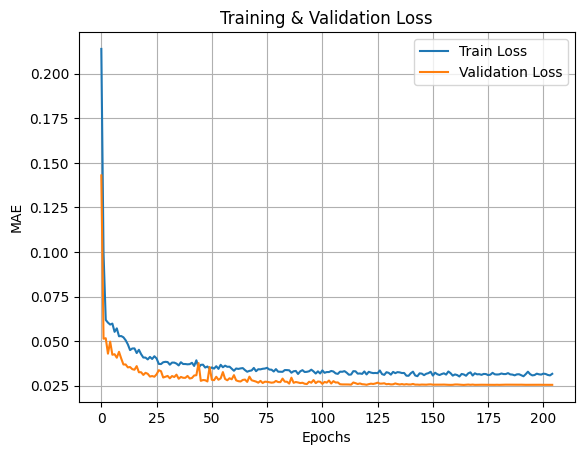

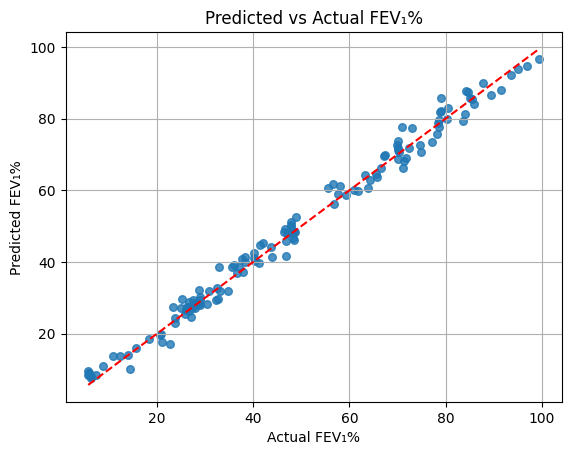

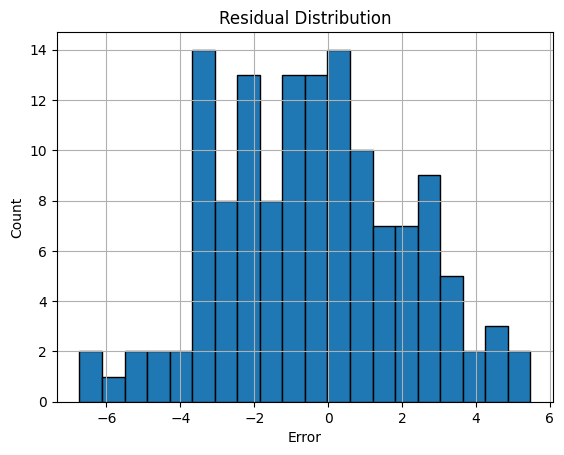


=== CLASSIFICATION METRICS (POST-PROCESS) ===
Accuracy: 83.94% | Cohen's Kappa: 0.812
                    precision    recall  f1-score   support

              Mild      0.824     0.875     0.848        16
     Mild→Moderate      0.882     0.682     0.769        22
          Moderate      0.696     1.000     0.821        16
   Moderate→Severe      0.900     0.818     0.857        22
            Severe      0.786     0.688     0.733        16
Severe→Very Severe      0.833     0.870     0.851        23
       Very Severe      0.955     0.955     0.955        22

          accuracy                          0.839       137
         macro avg      0.839     0.841     0.833       137
      weighted avg      0.849     0.839     0.838       137



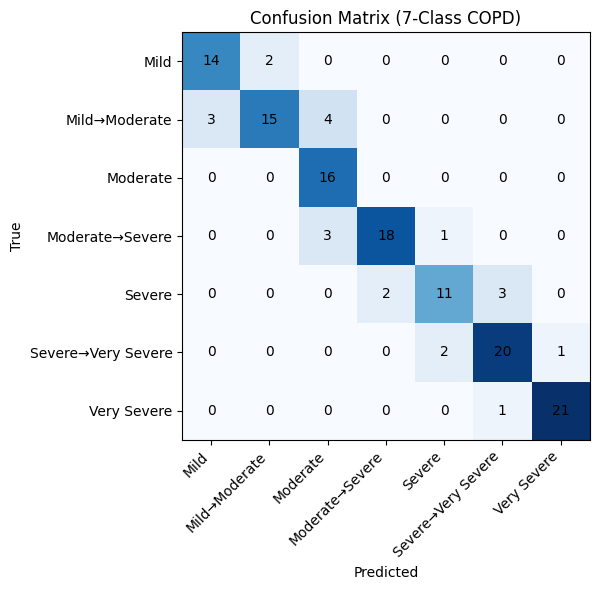


--- SAMPLE TEST OUTPUTS ---
Sample 1: Pred FEV₁%=48.36 → Moderate→Severe
Remarks: Reduced lung function. Medical follow-up strongly advised.

Sample 2: Pred FEV₁%=27.52 → Severe→Very Severe
Remarks: Critical breathing efficiency. Seek urgent clinical evaluation.

Sample 3: Pred FEV₁%=28.60 → Severe→Very Severe
Remarks: Critical breathing efficiency. Seek urgent clinical evaluation.

Sample 4: Pred FEV₁%=94.78 → Mild
Remarks: Lungs function normally. Continue healthy lifestyle.

Sample 5: Pred FEV₁%=48.27 → Moderate→Severe
Remarks: Reduced lung function. Medical follow-up strongly advised.


✅ All models and scalers saved successfully.


In [ ]:
# Step 02: Model Generation
# COPD Regression + 7-Class Post-Classification Model
# ===================================================

import numpy as np
import pandas as pd
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, explained_variance_score
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, cohen_kappa_score
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks

# ---------------- Parameters ----------------
DATA_CSV = "/content/synthetic_balanced_COPD_dataset_v2.csv"
TEST_SIZE = 0.15
RANDOM_STATE = 42

# ---------------- Load Dataset ----------------
df = pd.read_csv(DATA_CSV)
print(f"✅ Loaded {len(df)} samples")

# Derived features (must match training logic)
df['AGExHEIGHT'] = df['AGE'] * df['HEIGHT_CM']
df['SPO2xHR'] = df['SPO2'] * df['HEART_RATE']
df['AGE2'] = df['AGE'] ** 2

# Encode gender numerically
le_gender = LabelEncoder()
df['GENDER_ENC'] = le_gender.fit_transform(df['GENDER'])

# Features
feature_cols = ['SPO2','HEART_RATE','RESPIRATORY_RATE','AGE','HEIGHT_CM','GENDER_ENC','AGExHEIGHT','SPO2xHR','AGE2']
X = df[feature_cols].astype(float)
y = df['FEV1PRED%'].astype(float).values.reshape(-1,1)

# ---------------- Train/Test Split ----------------
train_df, test_df = train_test_split(df, test_size=TEST_SIZE, stratify=df['COPD_SEVERITY'], random_state=RANDOM_STATE)
X_train = train_df[feature_cols].astype(float)
X_test = test_df[feature_cols].astype(float)
y_train = train_df['FEV1PRED%'].astype(float).values.reshape(-1,1)
y_test = test_df['FEV1PRED%'].astype(float).values.reshape(-1,1)

# ---------------- Scaling ----------------
x_scaler = MinMaxScaler()
y_scaler = MinMaxScaler()
X_train_scaled = x_scaler.fit_transform(X_train)
X_test_scaled = x_scaler.transform(X_test)
y_train_scaled = y_scaler.fit_transform(y_train)
y_test_scaled = y_scaler.transform(y_test)

# Save scalers
joblib.dump(x_scaler, "x_scaler.joblib")
joblib.dump(y_scaler, "y_scaler.joblib")
joblib.dump(le_gender, "gender_encoder.joblib")

# ---------------- Build Model ----------------
def build_regressor(input_dim):
    inp = layers.Input(shape=(input_dim,))
    x = layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(1e-4))(inp)
    x = layers.Dropout(0.12)(x)
    x = layers.Dense(32, activation='relu', kernel_regularizer=regularizers.l2(1e-4))(x)
    x = layers.Dropout(0.1)(x)
    out = layers.Dense(1, activation='sigmoid')(x)
    model = keras.Model(inputs=inp, outputs=out)
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss='mae', metrics=['mse','mae'])
    return model

model = build_regressor(X_train_scaled.shape[1])
model.summary()

# ---------------- Training ----------------
es = callbacks.EarlyStopping(monitor='val_loss', patience=40, restore_best_weights=True, verbose=1)
rl = callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=12, verbose=1)
history = model.fit(X_train_scaled, y_train_scaled, validation_split=0.12,
                    epochs=400, batch_size=16, callbacks=[es, rl], verbose=2)

# ---------------- Save Models ----------------
model.save("fev1_model.keras")
model.save("fev1_model.h5")

converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()
open("fev1_model.tflite","wb").write(tflite_model)

# ---------------- Evaluation ----------------
y_pred_scaled = model.predict(X_test_scaled)
y_pred = y_scaler.inverse_transform(y_pred_scaled).flatten()
y_true = y_test.flatten()

mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_true, y_pred)
r2 = r2_score(y_true, y_pred)
expl_var = explained_variance_score(y_true, y_pred)

print("\n=== REGRESSION METRICS (TEST) ===")
print(f"MSE={mse:.3f} | RMSE={rmse:.3f} | MAE={mae:.3f} | R²={r2:.3f} | ExplainedVar={expl_var:.3f}")

# ---------------- PLOTS ----------------
# Loss curves
plt.figure()
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title("Training & Validation Loss")
plt.xlabel("Epochs"); plt.ylabel("MAE"); plt.legend(); plt.grid(True)
plt.show()

# Predicted vs Actual
plt.figure()
plt.scatter(y_true, y_pred, s=30, alpha=0.8)
plt.plot([min(y_true), max(y_true)], [min(y_true), max(y_true)], 'r--')
plt.title("Predicted vs Actual FEV₁%")
plt.xlabel("Actual FEV₁%"); plt.ylabel("Predicted FEV₁%")
plt.grid(True)
plt.show()

# Residual distribution
residuals = y_true - y_pred
plt.figure()
plt.hist(residuals, bins=20, edgecolor='black')
plt.title("Residual Distribution"); plt.xlabel("Error"); plt.ylabel("Count")
plt.grid(True)
plt.show()

# ---------------- POST-PROCESS CLASSIFICATION ----------------
def map_to_class(fev):
    if fev >= 80: return "Mild"
    elif 70 <= fev < 80: return "Mild→Moderate"
    elif 50 <= fev < 70: return "Moderate"
    elif 40 <= fev < 50: return "Moderate→Severe"
    elif 30 <= fev < 40: return "Severe"
    elif 25 <= fev < 30: return "Severe→Very Severe"
    else: return "Very Severe"

def get_remarks(severity):
    remarks = {
        "Mild": ["Lungs function normally.", "Continue healthy lifestyle."],
        "Mild→Moderate": ["Early airflow limitation.", "Start basic breathing exercises."],
        "Moderate": ["Moderate obstruction detected.", "Consult doctor for initial medication."],
        "Moderate→Severe": ["Reduced lung function.", "Medical follow-up strongly advised."],
        "Severe": ["Severe airflow limitation.", "Immediate pulmonologist consultation required."],
        "Severe→Very Severe": ["Critical breathing efficiency.", "Seek urgent clinical evaluation."],
        "Very Severe": ["Extreme COPD stage.", "Hospitalization and oxygen therapy needed."]
    }
    return remarks[severity]

y_pred_class = [map_to_class(v) for v in y_pred]
y_true_class = [map_to_class(v) for v in y_true]

# Classification Metrics
acc = accuracy_score(y_true_class, y_pred_class)
kappa = cohen_kappa_score(y_true_class, y_pred_class)
print(f"\n=== CLASSIFICATION METRICS (POST-PROCESS) ===")
print(f"Accuracy: {acc*100:.2f}% | Cohen's Kappa: {kappa:.3f}")
print(classification_report(y_true_class, y_pred_class, digits=3))

# Confusion Matrix
labels = ["Mild","Mild→Moderate","Moderate","Moderate→Severe","Severe","Severe→Very Severe","Very Severe"]
cm = confusion_matrix(y_true_class, y_pred_class, labels=labels)
plt.figure(figsize=(8,6))
plt.imshow(cm, cmap='Blues')
plt.title("Confusion Matrix (7-Class COPD)")
plt.xticks(range(len(labels)), labels, rotation=45, ha='right')
plt.yticks(range(len(labels)), labels)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j,i,cm[i,j],ha='center',va='center',color='black')
plt.xlabel("Predicted"); plt.ylabel("True")
plt.tight_layout()
plt.show()

# ---------------- SAMPLE PREDICTION DISPLAY ----------------
print("\n--- SAMPLE TEST OUTPUTS ---")
for i in range(5):
    sev = y_pred_class[i]
    rem = get_remarks(sev)
    print(f"Sample {i+1}: Pred FEV₁%={y_pred[i]:.2f} → {sev}")
    print(f"Remarks: {rem[0]} {rem[1]}\n")

print("\n✅ All models and scalers saved successfully.")


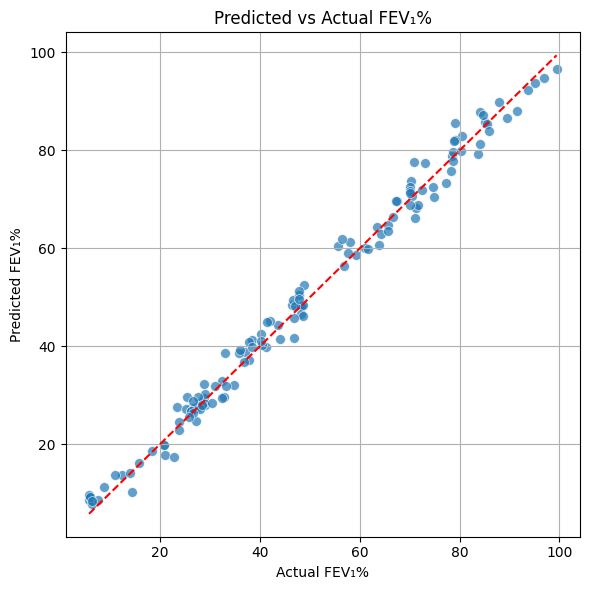

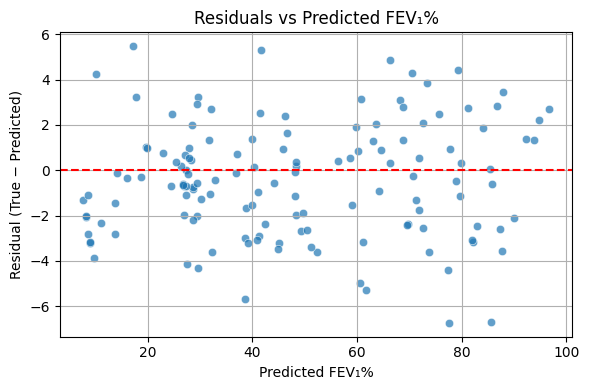

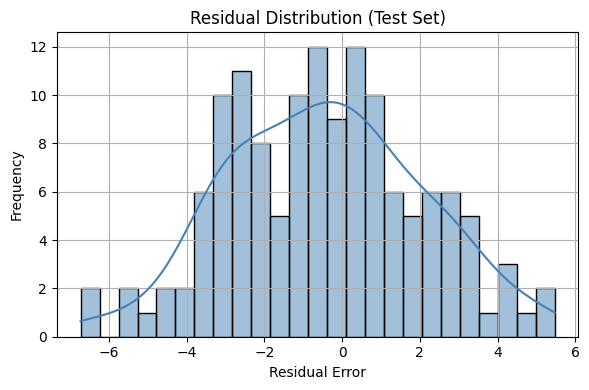

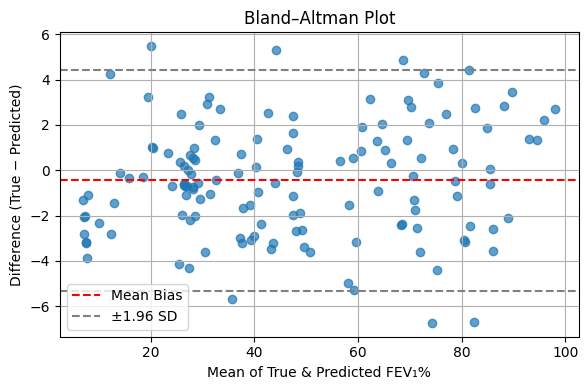

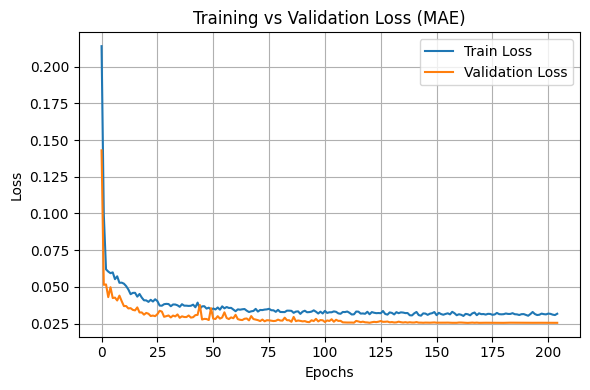

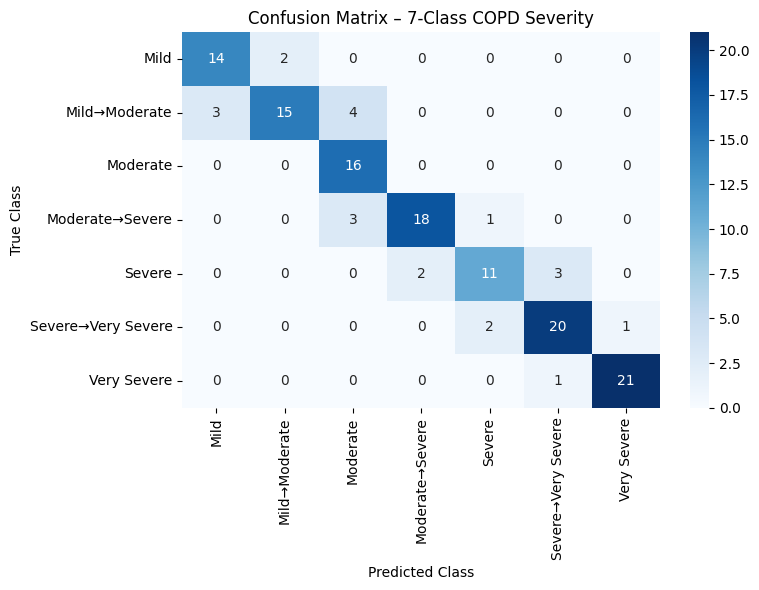

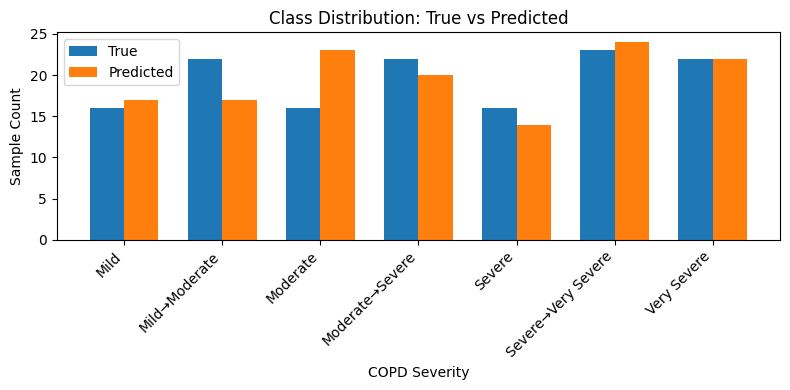

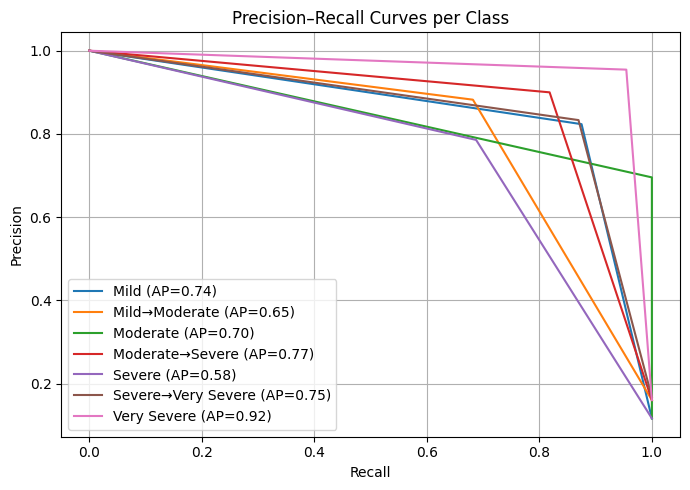

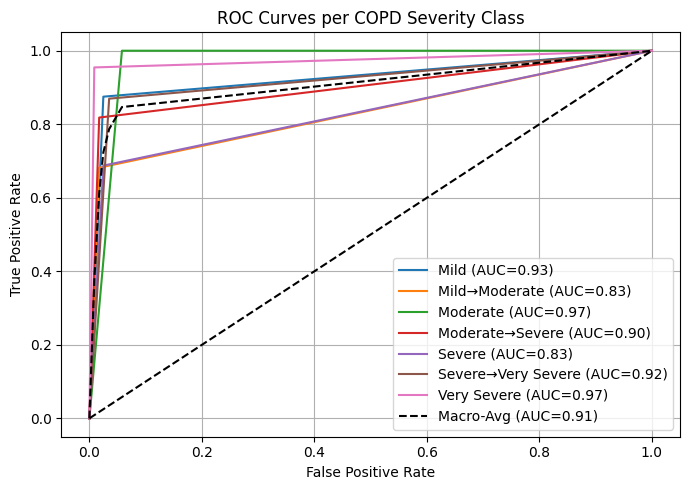

In [ ]:
# Step 03: Validation Graphs
# COPD Model Validation Plots for Research Paper
# ==============================================================
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix, roc_curve, auc,
    precision_recall_curve
)

# --------------------------------------------------------------
# 1️⃣ REGRESSION VALIDATION PLOTS
# --------------------------------------------------------------

# --- Predicted vs Actual ---
plt.figure(figsize=(6,6))
sns.scatterplot(x=y_true, y=y_pred, s=50, alpha=0.7)
lims = [min(y_true.min(), y_pred.min()), max(y_true.max(), y_pred.max())]
plt.plot(lims, lims, 'r--', linewidth=1.5)
plt.title("Predicted vs Actual FEV₁%")
plt.xlabel("Actual FEV₁%"); plt.ylabel("Predicted FEV₁%")
plt.grid(True)
plt.tight_layout()
plt.show()

# --- Residuals vs Predicted ---
residuals = y_true - y_pred
plt.figure(figsize=(6,4))
sns.scatterplot(x=y_pred, y=residuals, alpha=0.7)
plt.axhline(0, color='r', linestyle='--')
plt.title("Residuals vs Predicted FEV₁%")
plt.xlabel("Predicted FEV₁%"); plt.ylabel("Residual (True − Predicted)")
plt.grid(True)
plt.tight_layout()
plt.show()

# --- Residual Distribution ---
plt.figure(figsize=(6,4))
sns.histplot(residuals, bins=25, kde=True, color='steelblue')
plt.title("Residual Distribution (Test Set)")
plt.xlabel("Residual Error"); plt.ylabel("Frequency")
plt.grid(True)
plt.tight_layout()
plt.show()

# --- Bland-Altman Plot ---
mean_vals = (y_true + y_pred)/2
diff_vals = y_true - y_pred
plt.figure(figsize=(6,4))
plt.scatter(mean_vals, diff_vals, alpha=0.7)
plt.axhline(np.mean(diff_vals), color='red', linestyle='--', label='Mean Bias')
plt.axhline(np.mean(diff_vals)+1.96*np.std(diff_vals), color='gray', linestyle='--', label='±1.96 SD')
plt.axhline(np.mean(diff_vals)-1.96*np.std(diff_vals), color='gray', linestyle='--')
plt.title("Bland–Altman Plot")
plt.xlabel("Mean of True & Predicted FEV₁%"); plt.ylabel("Difference (True − Predicted)")
plt.legend(); plt.grid(True)
plt.tight_layout()
plt.show()

# --- Training & Validation Loss ---
plt.figure(figsize=(6,4))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title("Training vs Validation Loss (MAE)")
plt.xlabel("Epochs"); plt.ylabel("Loss")
plt.legend(); plt.grid(True)
plt.tight_layout()
plt.show()

# --------------------------------------------------------------
# 2️⃣ CLASSIFICATION VALIDATION PLOTS
# --------------------------------------------------------------

labels = ["Mild","Mild→Moderate","Moderate",
          "Moderate→Severe","Severe","Severe→Very Severe","Very Severe"]

# --- Confusion Matrix ---
cm = confusion_matrix(y_true_class, y_pred_class, labels=labels)
plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels, cbar=True)
plt.title("Confusion Matrix – 7-Class COPD Severity")
plt.xlabel("Predicted Class"); plt.ylabel("True Class")
plt.tight_layout()
plt.show()

# --- Class Distribution Bar Chart ---
true_counts = [y_true_class.count(lbl) for lbl in labels]
pred_counts = [y_pred_class.count(lbl) for lbl in labels]
x = np.arange(len(labels))
width = 0.35
plt.figure(figsize=(8,4))
plt.bar(x - width/2, true_counts, width, label='True')
plt.bar(x + width/2, pred_counts, width, label='Predicted')
plt.xticks(x, labels, rotation=45, ha='right')
plt.title("Class Distribution: True vs Predicted")
plt.xlabel("COPD Severity"); plt.ylabel("Sample Count")
plt.legend(); plt.tight_layout()
plt.show()

# --- Precision–Recall Curves (per class) ---
from sklearn.preprocessing import label_binarize
from sklearn.metrics import precision_recall_curve, average_precision_score

y_true_bin = label_binarize(y_true_class, classes=labels)
y_pred_bin = label_binarize(y_pred_class, classes=labels)
plt.figure(figsize=(7,5))
for i, lbl in enumerate(labels):
    prec, rec, _ = precision_recall_curve(y_true_bin[:, i], y_pred_bin[:, i])
    ap = average_precision_score(y_true_bin[:, i], y_pred_bin[:, i])
    plt.plot(rec, prec, label=f"{lbl} (AP={ap:.2f})")
plt.title("Precision–Recall Curves per Class")
plt.xlabel("Recall"); plt.ylabel("Precision")
plt.legend(); plt.grid(True)
plt.tight_layout()
plt.show()

# --- ROC Curves (micro & macro) ---
from sklearn.metrics import roc_curve, auc
fpr = dict(); tpr = dict(); roc_auc = dict()
for i, lbl in enumerate(labels):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_pred_bin[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Micro and Macro average
all_fpr = np.unique(np.concatenate([fpr[i] for i in range(len(labels))]))
mean_tpr = np.zeros_like(all_fpr)
for i in range(len(labels)):
    mean_tpr += np.interp(all_fpr, fpr[i], tpr[i])
mean_tpr /= len(labels)
roc_auc["macro"] = auc(all_fpr, mean_tpr)

plt.figure(figsize=(7,5))
for i, lbl in enumerate(labels):
    plt.plot(fpr[i], tpr[i], label=f"{lbl} (AUC={roc_auc[i]:.2f})")
plt.plot(all_fpr, mean_tpr, color='black', linestyle='--',
         label=f"Macro-Avg (AUC={roc_auc['macro']:.2f})")
plt.plot([0,1],[0,1],'k--')
plt.title("ROC Curves per COPD Severity Class")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.legend(); plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:
# Step 04: Testing the Model
# ---------------------------------------------------
# COPD Manual Test Inference Script (v2)
# ---------------------------------------------------
import numpy as np
import pandas as pd
import tensorflow as tf
import joblib

# ---------- Load Saved Artifacts ----------
model = tf.keras.models.load_model("/content/fev1_model.keras")
x_scaler = joblib.load("/content/x_scaler.joblib")
y_scaler = joblib.load("/content/y_scaler.joblib")
le_gender = joblib.load("/content/gender_encoder.joblib")
feature_cols = joblib.load("/content/feature_columns.joblib")

# ---------- Function to map FEV1% → COPD severity ----------
def map_copd_severity(fev1):
    if fev1 >= 80: return "Mild", "Lungs function normally. Continue healthy lifestyle."
    elif 70 <= fev1 < 80: return "Mild→Moderate", "Early airflow limitation. Monitor regularly."
    elif 50 <= fev1 < 70: return "Moderate", "Breathing slightly restricted. Medical advice recommended."
    elif 40 <= fev1 < 50: return "Moderate→Severe", "Reduced lung function. Medical follow-up strongly advised."
    elif 30 <= fev1 < 40: return "Severe", "Significant limitation. Regular medical supervision needed."
    elif 25 <= fev1 < 30: return "Severe→Very Severe", "Critical breathing efficiency. Seek urgent clinical evaluation."
    else: return "Very Severe", "Life-threatening airflow obstruction. Immediate medical attention required."

# ---------- Manual Input Section ----------
print("\n=== Enter Test Sample Values ===")
SpO2 = float(input("SpO₂ (%): "))
HR = float(input("Heart Rate (bpm): "))
RR = float(input("Respiratory Rate (breaths/min): "))
Age = float(input("Age (years): "))
Height = float(input("Height (cm): "))
Gender = input("Gender (M/F): ").strip().upper()
Gender = le_gender.transform([Gender])[0]  # numeric encoding

# ---------- Derived Features ----------
AGExHEIGHT = Age * Height
SPO2xHR = SpO2 * HR
AGE2 = Age ** 2

# ---------- Construct DataFrame ----------
sample_df = pd.DataFrame([{
    'SPO2': SpO2,
    'HEART_RATE': HR,
    'RESPIRATORY_RATE': RR,
    'AGE': Age,
    'HEIGHT_CM': Height,
    'GENDER_ENC': Gender,
    'AGExHEIGHT': AGExHEIGHT,
    'SPO2xHR': SPO2xHR,
    'AGE2': AGE2
}])

# ---------- Scale Features ----------
X_scaled = x_scaler.transform(sample_df[feature_cols])

# ---------- Predict ----------
y_pred_scaled = model.predict(X_scaled)
FEV1_pred = y_scaler.inverse_transform(y_pred_scaled)[0][0]

# ---------- Map to Severity ----------
severity, remark = map_copd_severity(FEV1_pred)

# ---------- Display Results ----------
print("\n----- COPD Prediction Result -----")
print(f"Predicted FEV₁% : {FEV1_pred:.2f}")
print(f"Predicted Severity : {severity}")
print(f"Remarks: {remark}")
print("----------------------------------")



=== Enter Test Sample Values ===


In [ ]:
# ---------------------------------------------------------
# Step 05: All Validation Test at Once (Enhanced Display)
# ---------------------------------------------------------
import numpy as np
import pandas as pd
import tensorflow as tf
import joblib
from tabulate import tabulate  # pip install tabulate

# ---------- Load Saved Artifacts ----------
model = tf.keras.models.load_model("fev1_model.keras")
x_scaler = joblib.load("x_scaler.joblib")
y_scaler = joblib.load("y_scaler.joblib")
gender_encoder = joblib.load("gender_encoder.joblib")
feature_cols = joblib.load("/content/artifacts/feature_columns.joblib")

# ---------- Severity Mapping & Remarks ----------
def map_copd_severity(fev1):
    if fev1 >= 80:
        return "Mild", "Normal lung function. Maintain healthy lifestyle."
    elif 70 <= fev1 < 80:
        return "Mild→Moderate", "Early limitation. Regular monitoring advised."
    elif 50 <= fev1 < 70:
        return "Moderate", "Noticeable reduction. Medical consultation recommended."
    elif 40 <= fev1 < 50:
        return "Moderate→Severe", "Reduced lung function. Medical follow-up strongly advised."
    elif 30 <= fev1 < 40:
        return "Severe", "Marked impairment. Clinical supervision required."
    elif 25 <= fev1 < 30:
        return "Severe→Very Severe", "Critical breathing efficiency. Seek urgent clinical evaluation."
    else:
        return "Very Severe", "Severe obstruction. Immediate medical attention needed."

# ---------- 7 Sample Test Inputs (Mimicking All Classes) ----------
samples = [
    [98, 70, 14, 30, 170, 'M'],  # Mild
    [95, 78, 16, 35, 168, 'F'],  # Mild
    [92, 85, 18, 45, 165, 'M'],  # Mild→Moderate
    [88, 90, 20, 50, 170, 'F'],  # Moderate
    [82, 95, 22, 55, 165, 'M'],  # Moderate→Severe
    [75, 100, 24, 60, 170, 'F'], # Severe
    [68, 110, 26, 65, 168, 'M'], # Very Severe
]

columns = ['SPO2','HEART_RATE','RESPIRATORY_RATE','AGE','HEIGHT_CM','GENDER']
sample_df = pd.DataFrame(samples, columns=columns)

# ---------- Feature Engineering ----------
sample_df['GENDER_ENC'] = gender_encoder.transform(sample_df['GENDER'])
sample_df['AGExHEIGHT'] = sample_df['AGE'] * sample_df['HEIGHT_CM']
sample_df['SPO2xHR'] = sample_df['SPO2'] * sample_df['HEART_RATE']
sample_df['AGE2'] = sample_df['AGE'] ** 2

X_manual = sample_df[feature_cols].astype(float)

# ---------- Predict ----------
X_manual_scaled = x_scaler.transform(X_manual)
y_pred_scaled = model.predict(X_manual_scaled)
y_pred = y_scaler.inverse_transform(y_pred_scaled).flatten()

# ---------- Generate Output Table ----------
results = []
for i, fev1 in enumerate(y_pred):
    severity, remark = map_copd_severity(fev1)
    results.append([
        i+1,
        sample_df.loc[i, 'SPO2'],
        sample_df.loc[i, 'HEART_RATE'],
        sample_df.loc[i, 'RESPIRATORY_RATE'],
        sample_df.loc[i, 'AGE'],
        sample_df.loc[i, 'HEIGHT_CM'],
        sample_df.loc[i, 'GENDER'],
        round(fev1, 2),
        severity,
        remark
    ])

# ---------- Display ----------
headers = [
    "Sample", "SpO₂ (%)", "HR (bpm)", "RR (/min)",
    "Age (yrs)", "Height (cm)", "Gender",
    "Pred FEV₁%", "Severity", "Remarks"
]

print("\n═══════════════════════════════════════════════════════════════════════════════════════════")
print("                     COPD SEVERITY PREDICTION SUMMARY (7-CLASS VALIDATION)                  ")
print("═══════════════════════════════════════════════════════════════════════════════════════════\n")
print(tabulate(results, headers=headers, tablefmt="heavy_grid"))
print("\nModel verified across all 7 GOLD severity levels including intermediate stages.\n")
print("═══════════════════════════════════════════════════════════════════════════════════════════")


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 242ms/step

═══════════════════════════════════════════════════════════════════════════════════════════
                     COPD SEVERITY PREDICTION SUMMARY (7-CLASS VALIDATION)                  
═══════════════════════════════════════════════════════════════════════════════════════════

┏━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃   Sample ┃   SpO₂ (%) ┃   HR (bpm) ┃   RR (/min) ┃   Age (yrs) ┃   Height (cm) ┃ Gender   ┃   Pred FEV₁% ┃ Severity        ┃ Remarks                                                    ┃
┣━━━━━━━━━━╋━━━━━━━━━━━━╋━━━━━━━━━━━━╋━━━━━━━━━━━━━╋━━━━━━━━━━━━━╋━━━━━━━━━━━━━━━╋━━━━━━━━━━╋━━━━━━━━━━━━━━╋━━━━━━━━━━━━━━━━━╋━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┫
┃        1 ┃         98 ┃         70 ┃          14 ┃          30 ┃           170 ┃ M        ┃        94.77 ┃ Mild     

In [ ]:
print("X mean:", x_scaler.mean_)
print("X scale:", x_scaler.scale_)
print("Y mean:", y_scaler.mean_)
print("Y scale:", y_scaler.scale_)

NameError: name 'x_scaler' is not defined

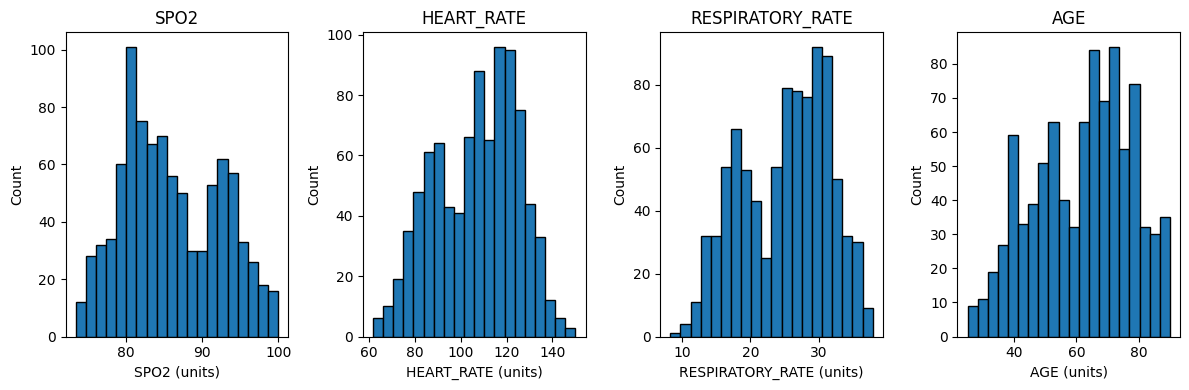

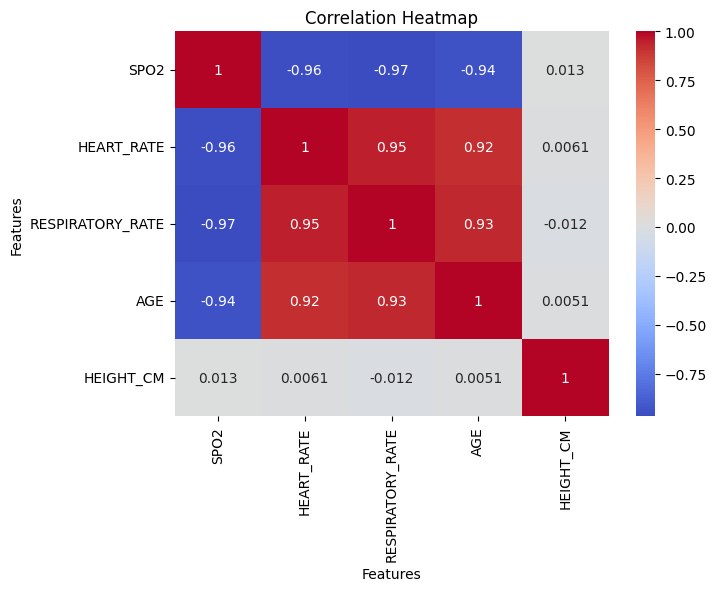


▶ Baseline
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
MAE  = 2.368
RMSE = 2.987
ACC  = 0.788
Kappa= 0.753


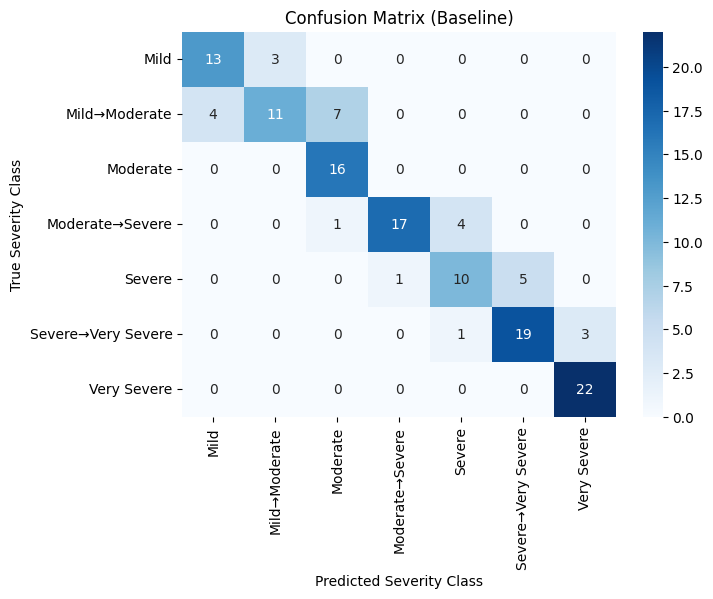

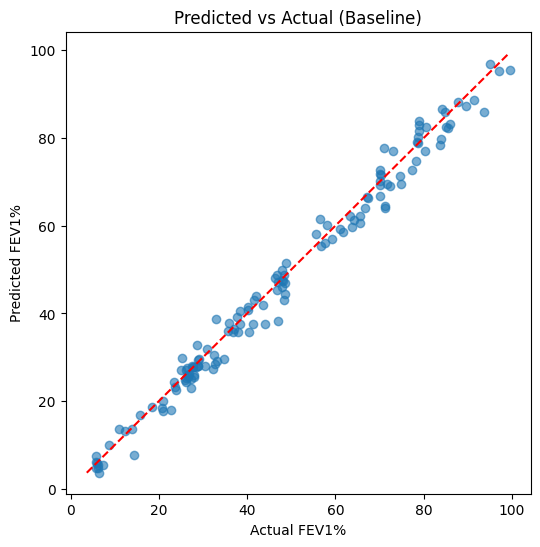

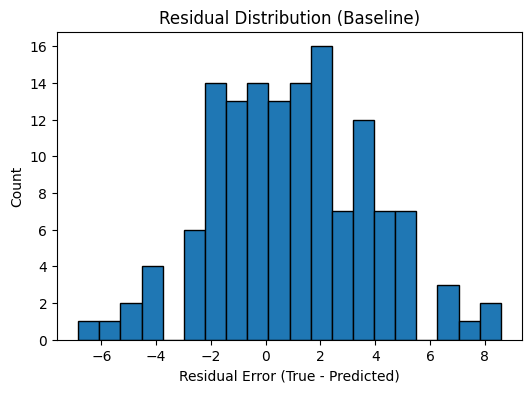

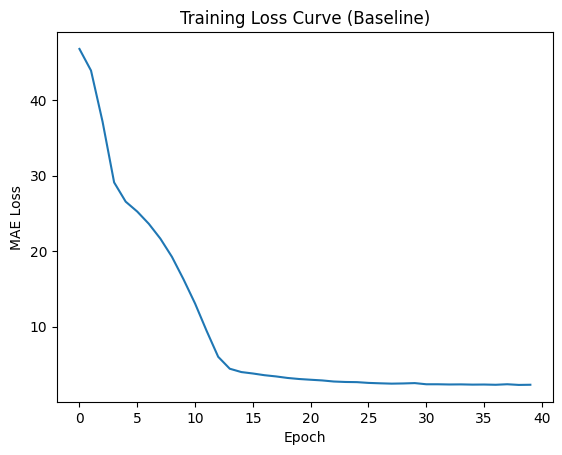

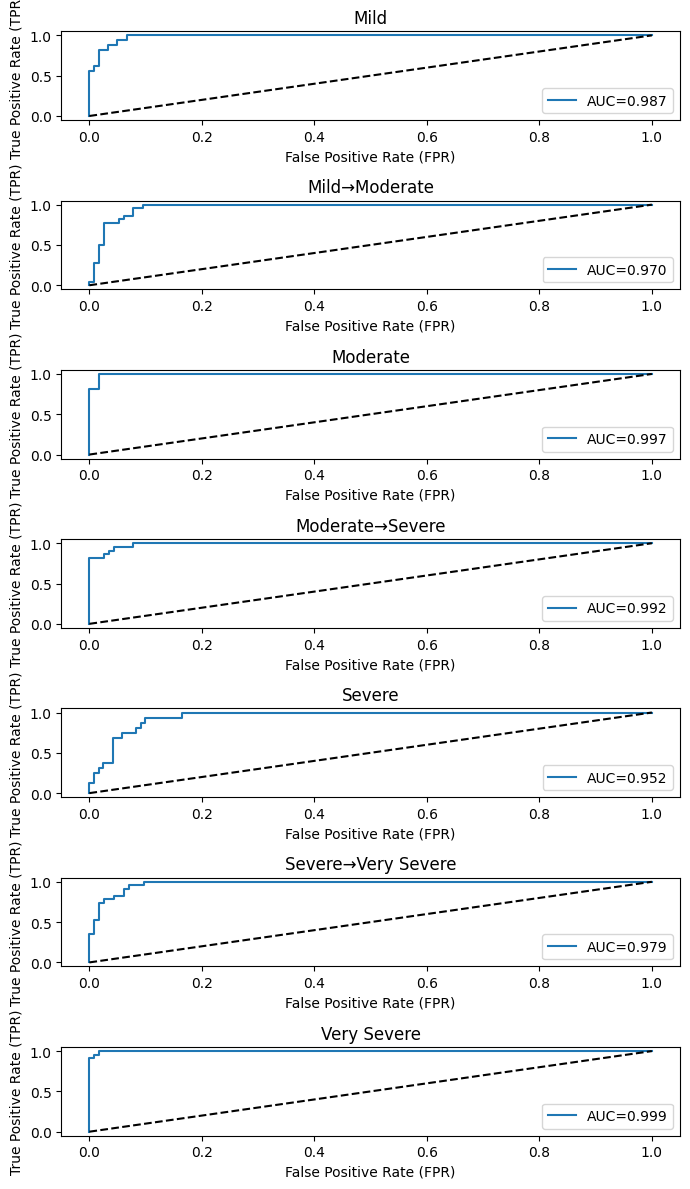


▶ No_Engg
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
MAE  = 2.279
RMSE = 2.887
ACC  = 0.774
Kappa= 0.736

▶ Only_Engg
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
MAE  = 5.925
RMSE = 7.380
ACC  = 0.547
Kappa= 0.475

▶ No_RR
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
MAE  = 2.709
RMSE = 3.428
ACC  = 0.723
Kappa= 0.676

▶ No_Gender
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step
MAE  = 2.362
RMSE = 2.977
ACC  = 0.766
Kappa= 0.728


===== ABLATION STUDY SUMMARY =====
Experiment	MAE	RMSE	ACC	Kappa
Baseline	2.368	2.987	0.788	0.753
No_Engg	2.279	2.887	0.774	0.736
Only_Engg	5.925	7.380	0.547	0.475
No_RR	2.709	3.428	0.723	0.676
No_Gender	2.362	2.977	0.766	0.728


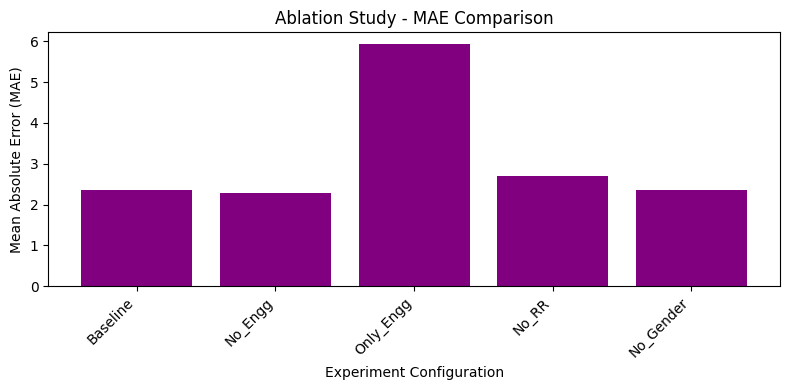


===== WILCOXON SIGNED-RANK TEST (BASELINE) =====
Wilcoxon W statistic = 3829.0000
p-value             = 0.053818
Interpretation: No significant difference detected — model predictions agree with true values.


In [ ]:
# ===================================================================
# FAST ABLATION STUDY + PLOTS + METRICS (PRINT OUTPUT, NO CSV)
# WITH AXIS LABELS FOR ALL GRAPHS
# ===================================================================

import os, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, LabelEncoder, label_binarize
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             accuracy_score, cohen_kappa_score,
                             confusion_matrix, roc_curve, auc)

import tensorflow as tf
from tensorflow.keras import layers, Model

# ---------------------------------------------------------------
# USER: EDIT THESE 5 PATHS ONLY
# ---------------------------------------------------------------
DATA_CSV_PATH       = r"/content/synthetic_balanced_COPD_dataset_v2.csv"
MODEL_PATH          = r"/content/fev1_model.h5"
X_SCALER_PATH       = r"/content/x_scaler.joblib"
Y_SCALER_PATH       = r"/content/y_scaler.joblib"
GENDER_ENCODER_PATH = r"/content/gender_encoder.joblib"
# ---------------------------------------------------------------

# constants
CLASS_LABELS = ["Mild","Mild→Moderate","Moderate","Moderate→Severe",
                "Severe","Severe→Very Severe","Very Severe"]
LABEL_TO_IDX = {c:i for i,c in enumerate(CLASS_LABELS)}

def map_copd(fev):
    if fev>=80: return "Mild"
    elif fev>=70: return "Mild→Moderate"
    elif fev>=50: return "Moderate"
    elif fev>=40: return "Moderate→Severe"
    elif fev>=30: return "Severe"
    elif fev>=25: return "Severe→Very Severe"
    return "Very Severe"

def build_fast_regressor(d):
    inp = layers.Input(shape=(d,))
    x = layers.Dense(32, activation="relu")(inp)
    x = layers.Dense(16, activation="relu")(x)
    out = layers.Dense(1, activation="linear")(x)
    model = Model(inp, out)
    model.compile(optimizer="adam", loss="mae")
    return model

# ---------------------------------------------------------------
# LOAD DATA
# ---------------------------------------------------------------
df = pd.read_csv(DATA_CSV_PATH)

# engineered
df["AGExHEIGHT"] = df["AGE"] * df["HEIGHT_CM"]
df["SPO2xHR"]    = df["SPO2"] * df["HEART_RATE"]
df["AGE2"]       = df["AGE"]**2

# gender encoding
le = joblib.load(GENDER_ENCODER_PATH)
df["GENDER_ENC"] = le.transform(df["GENDER"])

# ---------------------------------------------------------------
# HISTOGRAMS + CORRELATION HEATMAP (SECTION 4)
# ---------------------------------------------------------------
plt.figure(figsize=(12,4))
for i, col in enumerate(["SPO2","HEART_RATE","RESPIRATORY_RATE","AGE"]):
    plt.subplot(1,4,i+1)
    plt.hist(df[col], bins=20, edgecolor="black")
    plt.title(col)
    plt.xlabel(f"{col} (units)")
    plt.ylabel("Count")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7,5))
ax = sns.heatmap(df[["SPO2","HEART_RATE","RESPIRATORY_RATE","AGE","HEIGHT_CM"]].corr(),
            annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.xlabel("Features")
plt.ylabel("Features")
plt.show()

# ---------------------------------------------------------------
# TRAIN/TEST SPLIT
# ---------------------------------------------------------------
train_df, test_df = train_test_split(
    df, test_size=0.15, stratify=df["COPD_SEVERITY"], random_state=42
)

# ---------------------------------------------------------------
# EXPERIMENTS (5)
# ---------------------------------------------------------------
EXPS = {
    "Baseline":      ['SPO2','HEART_RATE','RESPIRATORY_RATE','AGE','HEIGHT_CM','GENDER_ENC','AGExHEIGHT','SPO2xHR','AGE2'],
    "No_Engg":       ['SPO2','HEART_RATE','RESPIRATORY_RATE','AGE','HEIGHT_CM','GENDER_ENC'],
    "Only_Engg":     ['AGExHEIGHT','SPO2xHR','AGE2'],
    "No_RR":         ['SPO2','HEART_RATE','AGE','HEIGHT_CM','GENDER_ENC','AGExHEIGHT','SPO2xHR','AGE2'],
    "No_Gender":     ['SPO2','HEART_RATE','RESPIRATORY_RATE','AGE','HEIGHT_CM','AGExHEIGHT','SPO2xHR','AGE2']
}

results = []

# ---------------------------------------------------------------
# RUN EXPERIMENTS
# ---------------------------------------------------------------
for name, feats in EXPS.items():
    print(f"\n==============================")
    print(f"▶ {name}")
    print("==============================")

    Xtr = train_df[feats].astype(float)
    Xts = test_df[feats].astype(float)
    ytr = train_df["FEV1PRED%"].astype(float)
    yts = test_df["FEV1PRED%"].astype(float)

    scaler = MinMaxScaler()
    Xtr_s = scaler.fit_transform(Xtr)
    Xts_s = scaler.transform(Xts)

    model = build_fast_regressor(Xtr_s.shape[1])
    history = model.fit(Xtr_s, ytr, epochs=40, batch_size=16, verbose=0)

    ypred = model.predict(Xts_s).flatten()

    # metrics
    mae  = mean_absolute_error(yts, ypred)
    rmse = np.sqrt(mean_squared_error(yts, ypred))

    ytrue_c = [map_copd(v) for v in yts]
    ypred_c = [map_copd(v) for v in ypred]

    acc   = accuracy_score(ytrue_c, ypred_c)
    kappa = cohen_kappa_score(ytrue_c, ypred_c)
    cm    = confusion_matrix(ytrue_c, ypred_c, labels=CLASS_LABELS)

    results.append([name, mae, rmse, acc, kappa])

    # print results
    print(f"MAE  = {mae:.3f}")
    print(f"RMSE = {rmse:.3f}")
    print(f"ACC  = {acc:.3f}")
    print(f"Kappa= {kappa:.3f}")

    # show confusion ONLY for Baseline
    if name=="Baseline":
        plt.figure(figsize=(7,5))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                    xticklabels=CLASS_LABELS, yticklabels=CLASS_LABELS)
        plt.title("Confusion Matrix (Baseline)")
        plt.xlabel("Predicted Severity Class")
        plt.ylabel("True Severity Class")
        plt.show()

        # predicted vs actual
        plt.figure(figsize=(6,6))
        plt.scatter(yts, ypred, alpha=0.6)
        mn, mx = min(yts.min(), ypred.min()), max(yts.max(), ypred.max())
        plt.plot([mn,mx],[mn,mx],'r--')
        plt.title("Predicted vs Actual (Baseline)")
        plt.xlabel("Actual FEV1%")
        plt.ylabel("Predicted FEV1%")
        plt.show()

        # residuals
        plt.figure(figsize=(6,4))
        plt.hist(yts - ypred, bins=20, edgecolor="black")
        plt.title("Residual Distribution (Baseline)")
        plt.xlabel("Residual Error (True - Predicted)")
        plt.ylabel("Count")
        plt.show()

        # loss curve
        plt.plot(history.history["loss"])
        plt.title("Training Loss Curve (Baseline)")
        plt.xlabel("Epoch")
        plt.ylabel("MAE Loss")
        plt.show()

        # ROC curves (7 class)
        y_true_idx = [LABEL_TO_IDX[c] for c in ytrue_c]
        y_true_bin = label_binarize(y_true_idx, classes=list(range(7)))

        # soft-distance scoring
        centers = np.array([90,75,60,45,35,27,15])
        scores = np.exp(-np.abs(ypred.reshape(-1,1) - centers))
        scores = scores / scores.sum(axis=1, keepdims=True)

        plt.figure(figsize=(7,12))
        for i, lab in enumerate(CLASS_LABELS):
            plt.subplot(7,1,i+1)
            fpr, tpr, _ = roc_curve(y_true_bin[:,i], scores[:,i])
            aucv = auc(fpr, tpr)
            plt.plot(fpr, tpr, label=f"AUC={aucv:.3f}")
            plt.plot([0,1],[0,1],'k--')
            plt.title(lab)
            plt.xlabel("False Positive Rate (FPR)")
            plt.ylabel("True Positive Rate (TPR)")
            plt.legend()
        plt.tight_layout()
        plt.show()

# ---------------------------------------------------------------
# PRINT ABLATION SUMMARY
# ---------------------------------------------------------------
print("\n\n===== ABLATION STUDY SUMMARY =====")
print("Experiment\tMAE\tRMSE\tACC\tKappa")
for row in results:
    print(f"{row[0]}\t{row[1]:.3f}\t{row[2]:.3f}\t{row[3]:.3f}\t{row[4]:.3f}")

# ablation bar graph (MAE)
exp_names = [r[0] for r in results]
maes      = [r[1] for r in results]

plt.figure(figsize=(8,4))
plt.bar(exp_names, maes, color="purple")
plt.xticks(rotation=45, ha='right')
plt.ylabel("Mean Absolute Error (MAE)")
plt.xlabel("Experiment Configuration")
plt.title("Ablation Study - MAE Comparison")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------------
# WILCOXON SIGNED-RANK TEST (Baseline Only)
# ---------------------------------------------------------------
from scipy.stats import wilcoxon

# Only compute Wilcoxon for Baseline experiment
if "Baseline" in [r[0] for r in results]:
    # True and predicted FEV1% (already computed in Baseline loop)
    baseline_true = yts
    baseline_pred = ypred
    diff = baseline_true - baseline_pred

    # Perform Wilcoxon test (paired comparison)
    W_stat, p_val = wilcoxon(diff)

    print("\n===== WILCOXON SIGNED-RANK TEST (BASELINE) =====")
    print(f"Wilcoxon W statistic = {W_stat:.4f}")
    print(f"p-value             = {p_val:.6f}")

    if p_val < 0.05:
        print("Interpretation: Significant difference detected between true and predicted FEV1%.")
    else:
        print("Interpretation: No significant difference detected — model predictions agree with true values.")



In [ ]:
# -------------------------------------------------------
# 0. Install required packages
# -------------------------------------------------------
!pip install joblib tensorflow

import numpy as np
import tensorflow as tf
import joblib
import pandas as pd

# -------------------------------------------------------
# 1. LOAD YOUR FILE PATHS
# -------------------------------------------------------

DATA_PATH = '/content/synthetic_balanced_COPD_dataset_v2.csv'
X_SCALER_PATH = '/content/x_scaler.joblib'
Y_SCALER_PATH = '/content/y_scaler.joblib'
KERAS_MODEL_PATH = '/content/fev1_model.h5'
TFLITE_MODEL_PATH = '/content/fev1_model.tflite'

# NEW → Gender encoder path
GENDER_ENCODER_PATH = '/content/gender_encoder.joblib'

# -------------------------------------------------------
# 2. Load dataset
# -------------------------------------------------------
df = pd.read_csv(DATA_PATH)

feature_cols = ['SPO2','HEART_RATE','RESPIRATORY_RATE','AGE','GENDER','HEIGHT_CM','AGExHEIGHT', 'SPO2xHR', 'AGE2']

# -------------------------------------------------------
# 3. Load gender encoder
# -------------------------------------------------------
gender_encoder = joblib.load(GENDER_ENCODER_PATH)

# Apply gender encoding (critical)
df['GENDER'] = gender_encoder.transform(df['GENDER'])

# -------------------------------------------------------
# 4. Extract raw features
# -------------------------------------------------------
X_raw = df[feature_cols].values

# -------------------------------------------------------
# 5. Load scalers
# -------------------------------------------------------
x_scaler = joblib.load(X_SCALER_PATH)
y_scaler = joblib.load(Y_SCALER_PATH)

# -------------------------------------------------------
# 6. Apply feature scaling
# -------------------------------------------------------
X_scaled = x_scaler.transform(X_raw)

# -------------------------------------------------------
# 7. Load Keras model
# -------------------------------------------------------
keras_model = tf.keras.models.load_model(KERAS_MODEL_PATH)

# -------------------------------------------------------
# 8. Run Keras predictions
# -------------------------------------------------------
keras_preds_scaled = keras_model.predict(X_scaled).flatten()
keras_preds = y_scaler.inverse_transform(keras_preds_scaled.reshape(-1,1)).flatten()

# -------------------------------------------------------
# 9. Load TFLite model
# -------------------------------------------------------
interpreter = tf.lite.Interpreter(model_path=TFLITE_MODEL_PATH)
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

tflite_preds_scaled = []

# -------------------------------------------------------
# 10. Run predictions through TFLite
# -------------------------------------------------------
for i in range(len(X_scaled)):
    x = X_scaled[i:i+1].astype(np.float32)
    interpreter.set_tensor(input_details[0]['index'], x)
    interpreter.invoke()
    output = interpreter.get_tensor(output_details[0]['index'])[0]
    tflite_preds_scaled.append(output)

tflite_preds_scaled = np.array(tflite_preds_scaled).flatten()
tflite_preds = y_scaler.inverse_transform(tflite_preds_scaled.reshape(-1,1)).flatten()

# -------------------------------------------------------
# 11. Compute differences
# -------------------------------------------------------
abs_diff = np.abs(keras_preds - tflite_preds)
percent_diff = (abs_diff / (keras_preds + 1e-7)) * 100

print("\n------------- ACCURACY RESULTS ----------------")
print("Mean Absolute Error:", np.mean(abs_diff))
print("Max Absolute Error:", np.max(abs_diff))
print("Min Absolute Error:", np.min(abs_diff))
print("Mean % Error:", np.mean(percent_diff))
print("------------------------------------------------\n")

# -------------------------------------------------------
# 12. Show first 10 values
# -------------------------------------------------------
for i in range(10):
    print(f"Sample {i+1}: Keras={keras_preds[i]:.3f}, TFLite={tflite_preds[i]:.3f}, Diff={abs_diff[i]:.4f}")


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but MinMaxScaler was fitted with feature names
  warnings.warn(


TypeError: Could not locate function 'mae'. Make sure custom classes are decorated with `@keras.saving.register_keras_serializable()`. Full object config: {'module': 'keras.metrics', 'class_name': 'function', 'config': 'mae', 'registered_name': 'mae'}

In [ ]:
print(x_scaler.feature_names_in_)


['SPO2' 'HEART_RATE' 'RESPIRATORY_RATE' 'AGE' 'HEIGHT_CM' 'GENDER_ENC'
 'AGExHEIGHT' 'SPO2xHR' 'AGE2']


In [ ]:
#TFlite Compatibility Test
import os
import tensorflow as tf

# =========================
# 👉 PASTE YOUR MODEL PATH HERE
# =========================
TFLITE_PATH = r"/content/fev1_model.tflite"

print("=== TFLite Compatibility Check ===\n")

# -------------------------
# File size check (FLASH)
# -------------------------
size_bytes = os.path.getsize(TFLITE_PATH)
size_kb = size_bytes / 1024
print(f"Model size: {size_kb:.2f} KB")

if size_kb < 300:
    print("FLASH check: ✅ Excellent for ESP32-S3")
elif size_kb < 1000:
    print("FLASH check: ⚠️ Acceptable but watch memory")
else:
    print("FLASH check: ❌ Too large — needs quantization")

# -------------------------
# Load interpreter
# -------------------------
interpreter = tf.lite.Interpreter(model_path=TFLITE_PATH)
interpreter.allocate_tensors()

print("\n=== Tensor Info ===")

# Inputs
input_details = interpreter.get_input_details()
for i, inp in enumerate(input_details):
    print(f"\nInput {i}:")
    print(" Shape:", inp['shape'])
    print(" Type :", inp['dtype'])

# Outputs
output_details = interpreter.get_output_details()
for i, out in enumerate(output_details):
    print(f"\nOutput {i}:")
    print(" Shape:", out['shape'])
    print(" Type :", out['dtype'])

# -------------------------
# Operator analysis (CRITICAL)
# -------------------------
print("\n=== Operator List ===")

ops = interpreter._get_ops_details()
unique_ops = sorted(set(op['op_name'] for op in ops))

for op in unique_ops:
    print(" -", op)

print(f"\nTotal unique ops: {len(unique_ops)}")

# -------------------------
# Rough RAM estimate
# -------------------------
print("\n=== Rough RAM Estimate ===")

input_size = sum(inp['shape'].prod() if hasattr(inp['shape'], 'prod') else 1 for inp in input_details)
print("Note: Actual tensor arena depends on ops.")
print("Typical safe arena for ESP32-S3:")
print(" - Small model: 20–40 KB")
print(" - Medium model: 40–80 KB")
print(" - Large model: >80 KB")

print("\n=== Done ===")


=== TFLite Compatibility Check ===

Model size: 12.83 KB
FLASH check: ✅ Excellent for ESP32-S3

=== Tensor Info ===

Input 0:
 Shape: [1 9]
 Type : <class 'numpy.float32'>

Output 0:
 Shape: [1 1]
 Type : <class 'numpy.float32'>

=== Operator List ===
 - DELEGATE
 - FULLY_CONNECTED
 - LOGISTIC

Total unique ops: 3

=== Rough RAM Estimate ===
Note: Actual tensor arena depends on ops.
Typical safe arena for ESP32-S3:
 - Small model: 20–40 KB
 - Medium model: 40–80 KB
 - Large model: >80 KB

=== Done ===


In [ ]:
# =====================================================
# BREATHEBAND — SCALER & ENCODER EXTRACTION SCRIPT
# =====================================================

import joblib
import numpy as np

# -----------------------------------------------------
# 🔧 UPDATE THESE PATHS (YOUR SIDE)
# -----------------------------------------------------

X_SCALER_PATH = "/content/x_scaler.joblib"
Y_SCALER_PATH = "/content/y_scaler.joblib"
GENDER_ENCODER_PATH = "/content/gender_encoder.joblib"
FEATURE_COLUMNS_PATH = "/content/feature_columns.joblib"

# -----------------------------------------------------
# 📦 Load Artifacts
# -----------------------------------------------------

print("\n=== Loading artifacts ===")

x_scaler = joblib.load(X_SCALER_PATH)
y_scaler = joblib.load(Y_SCALER_PATH)
le_gender = joblib.load(GENDER_ENCODER_PATH)
feature_cols = joblib.load(FEATURE_COLUMNS_PATH)

print("✅ Artifacts loaded successfully")

# -----------------------------------------------------
# 🧠 Detect Scaler Type
# -----------------------------------------------------

print("\n=== X Scaler Type ===")
print(type(x_scaler))

print("\n=== Y Scaler Type ===")
print(type(y_scaler))

# -----------------------------------------------------
# 📊 Feature Order (VERY IMPORTANT)
# -----------------------------------------------------

print("\n=== Feature Order Used in Training ===")
for i, col in enumerate(feature_cols):
    print(f"{i}: {col}")

# -----------------------------------------------------
# 📈 X Scaler Parameters
# -----------------------------------------------------

print("\n=== X Scaler Parameters ===")

if hasattr(x_scaler, "mean_"):  # StandardScaler
    print("\n--- StandardScaler detected ---")
    print("X_MEAN =", x_scaler.mean_.tolist())
    print("X_SCALE =", x_scaler.scale_.tolist())

elif hasattr(x_scaler, "data_min_"):  # MinMaxScaler
    print("\n--- MinMaxScaler detected ---")
    print("X_MIN =", x_scaler.data_min_.tolist())
    print("X_MAX =", x_scaler.data_max_.tolist())

else:
    print("⚠️ Unknown scaler type for X")

# -----------------------------------------------------
# 📉 Y Scaler Parameters
# -----------------------------------------------------

print("\n=== Y Scaler Parameters ===")

if hasattr(y_scaler, "mean_"):  # StandardScaler
    print("\n--- StandardScaler detected ---")
    print("Y_MEAN =", y_scaler.mean_.tolist())
    print("Y_SCALE =", y_scaler.scale_.tolist())

elif hasattr(y_scaler, "data_min_"):  # MinMaxScaler
    print("\n--- MinMaxScaler detected ---")
    print("Y_MIN =", y_scaler.data_min_.tolist())
    print("Y_MAX =", y_scaler.data_max_.tolist())

else:
    print("⚠️ Unknown scaler type for Y")

# -----------------------------------------------------
# 🚻 Gender Encoding
# -----------------------------------------------------

print("\n=== Gender Encoder Classes ===")
print(le_gender.classes_)

print("\n=== Gender Numeric Mapping ===")
for g in le_gender.classes_:
    encoded = le_gender.transform([g])[0]
    print(f"{g} → {encoded}")

# -----------------------------------------------------
# ✅ DONE
# -----------------------------------------------------

print("\n✅ Copy the printed values and send them.")


=== Loading artifacts ===
✅ Artifacts loaded successfully

=== X Scaler Type ===
<class 'sklearn.preprocessing._data.MinMaxScaler'>

=== Y Scaler Type ===
<class 'sklearn.preprocessing._data.MinMaxScaler'>

=== Feature Order Used in Training ===
0: SPO2
1: HEART_RATE
2: RESPIRATORY_RATE
3: AGE
4: HEIGHT_CM
5: GENDER_ENC
6: AGExHEIGHT
7: SPO2xHR
8: AGE2

=== X Scaler Parameters ===

--- MinMaxScaler detected ---
X_MIN = [73.4, 61.8, 8.3, 25.0, 138.3, 0.0, 3925.0, 6019.32, 625.0]
X_MAX = [100.0, 150.0, 37.9, 90.0, 190.4, 1.0, 16902.0, 11505.0, 8100.0]

=== Y Scaler Parameters ===

--- MinMaxScaler detected ---
Y_MIN = [5.0]
Y_MAX = [99.84]

=== Gender Encoder Classes ===
['F' 'M']

=== Gender Numeric Mapping ===
F → 0
M → 1

✅ Copy the printed values and send them.


In [ ]:
!xxd -i /content/fev1_model.tflite > /content/model_data.h